# EDA auditada — comparación Centro v2 vs v3

La v3 conserva todas las columnas de la v2 y agrega variables auditadas. Este notebook cuantifica el efecto de las decisiones respaldadas; no oculta los 25 P0 pendientes.

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = sns.color_palette('colorblind')

def find_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / 'data').exists() and (candidate / 'src').exists(): return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio')
ROOT = find_root()
v2 = pd.read_csv(ROOT / 'data/processed/zonaprop_v2_eda_centro_v2_barrios.csv.gz', low_memory=False)
v3 = pd.read_csv(ROOT / 'data/processed/zonaprop_v2_eda_centro_v3_auditado.csv.gz', low_memory=False)
audit = pd.read_csv(ROOT / 'reports/tables/auditoria_extremos_centro_v2.csv', low_memory=False)

## 1. Integridad y alcance de las decisiones

In [7]:
assert len(v2) == len(v3) == 9_582
assert v2.property_id.equals(v3.property_id)
pd.testing.assert_frame_equal(v2, v3[v2.columns], check_dtype=True, check_exact=True)
summary = pd.Series({
    'Filas conservadas': len(v3),
    'Targets auditados utilizables': int(v3.apto_eda_target_auditado.sum()),
    'Targets no observables': int((~v3.apto_eda_target_auditado).sum()),
    'Filas con decisión aplicada': int(v3.auditoria_decisiones_aplicadas.fillna('').ne('').sum()),
    'P0 todavía pendientes': int(v3.auditoria_p0_pendiente.sum()),
}, name='n')
display(summary.to_frame())

,n
Filas conservadas,9582
Targets auditados utilizables,9542
Targets no observables,40
Filas con decisión aplicada,52
P0 todavía pendientes,15


## 2. Efecto sobre el target

,v2_original,v3_auditada
count,"9,582.00","9,542.00"
mean,"164,771.11","159,104.05"
std,"630,310.67","120,956.94"
min,1.00,"1,111.00"
1%,"25,000.00","28,205.00"
25%,"68,000.00","68,940.00"
50%,"125,000.00","127,000.00"
75%,"212,470.00","213,719.00"
99%,"546,700.00","546,700.00"
max,"60,708,000.00","1,950,000.00"


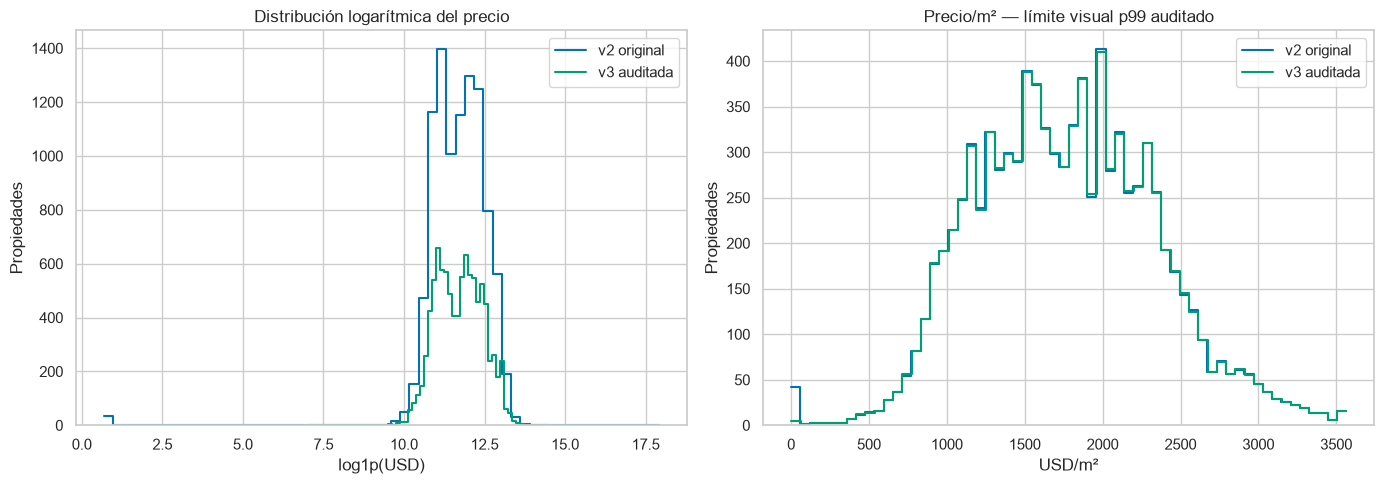

In [8]:
before = pd.to_numeric(v2.precio_ultimo, errors='coerce')
after = pd.to_numeric(v3.precio_auditado, errors='coerce')
comparison = pd.DataFrame({
    'v2_original': before.describe(percentiles=[.01,.25,.5,.75,.99]),
    'v3_auditada': after.describe(percentiles=[.01,.25,.5,.75,.99]),
})
display(comparison.style.format('{:,.2f}'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for values, label, color in [(before, 'v2 original', PALETTE[0]), (after, 'v3 auditada', PALETTE[2])]:
    sns.histplot(np.log1p(values.dropna()), bins=60, element='step', fill=False, label=label, color=color, ax=axes[0])
axes[0].set(title='Distribución logarítmica del precio', xlabel='log1p(USD)', ylabel='Propiedades')
axes[0].legend()
pm2_before = pd.to_numeric(v2.precio_m2_observado, errors='coerce')
pm2_after = pd.to_numeric(v3.precio_m2_auditado, errors='coerce')
limit = pm2_after.quantile(.99)
sns.histplot(pm2_before[pm2_before <= limit], bins=60, element='step', fill=False, label='v2 original', color=PALETTE[0], ax=axes[1])
sns.histplot(pm2_after[pm2_after <= limit], bins=60, element='step', fill=False, label='v3 auditada', color=PALETTE[2], ax=axes[1])
axes[1].set(title='Precio/m² — límite visual p99 auditado', xlabel='USD/m²', ylabel='Propiedades')
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Resultados territoriales con target auditado

,n,precio_mediano,precio_m2_mediano
barrio_oficial_geo,,,
ALBERTO OLMEDO,866,"USD 145,100","USD 1,955"
NTRA SRA DE LOURDES,745,"USD 119,000","USD 1,884"
JORGE CURA,23,"USD 162,000","USD 1,825"
CENTRO,5189,"USD 135,000","USD 1,789"
DEL ABASTO,591,"USD 129,000","USD 1,774"
REPUBLICA DE LA 6TA,552,"USD 65,000","USD 1,444"
ECHESORTU,428,"USD 65,000","USD 1,433"
LUIS AGOTE,229,"USD 55,000","USD 1,423"
PARQUE CASADO,17,"USD 58,000","USD 1,250"


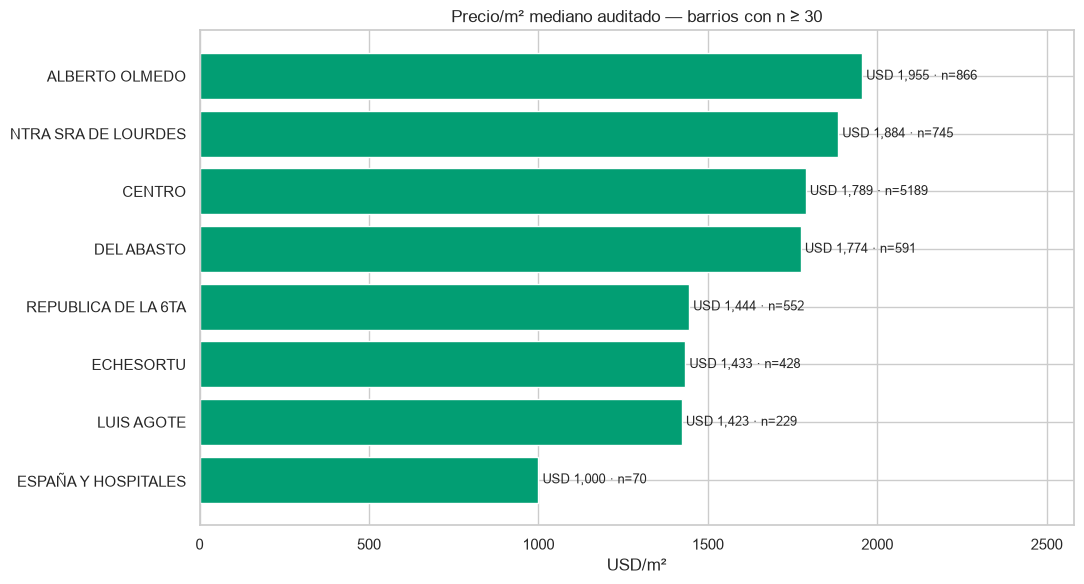

In [9]:
usable = v3.loc[v3.apto_eda_target_auditado & v3.barrio_geo_apto_eda_preliminar].copy()
stats = (usable.groupby('barrio_oficial_geo')
    .agg(n=('property_id','size'), precio_mediano=('precio_auditado','median'), precio_m2_mediano=('precio_m2_auditado','median'))
    .sort_values('precio_m2_mediano', ascending=False))
display(stats.style.format({'precio_mediano':'USD {:,.0f}', 'precio_m2_mediano':'USD {:,.0f}'}))

stable = stats.query('n >= 30').sort_values('precio_m2_mediano')
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(stable.index, stable.precio_m2_mediano, color=PALETTE[2])
ax.bar_label(bars, labels=[f'USD {v:,.0f} · n={n}' for v,n in zip(stable.precio_m2_mediano,stable.n)], padding=3, fontsize=9)
ax.set(title='Precio/m² mediano auditado — barrios con n ≥ 30', xlabel='USD/m²', ylabel='')
ax.set_xlim(0, stable.precio_m2_mediano.max()*1.32)
plt.tight_layout(); plt.show()

## 4. Pendientes P0

In [10]:
pending_ids = set(v3.loc[v3.auditoria_p0_pendiente, 'property_id'])
pending = audit.loc[audit.property_id.isin(pending_ids)].copy()
print(f'Casos P0 pendientes: {len(pending):,}')
pending_flags = (pending.audit_flags.str.split(' | ', regex=False).explode().value_counts().rename('n'))
display(pending_flags.to_frame())
display(pending[['property_id','direccion_exacta','precio_ultimo','superficie_total_m2','superficie_cubierta_m2','banos','cocheras','antiguedad','audit_flags']])

Casos P0 pendientes: 15


,n
audit_flags,
cubierta_mayor_total,11
precio_m2_fuera_p01_p99,5
superficie_fuera_p01_p99,4
superficie_mayor_1000,4
coordenada_pendiente,1


,property_id,direccion_exacta,precio_ultimo,superficie_total_m2,superficie_cubierta_m2,banos,cocheras,antiguedad,audit_flags
3,prop_4263c53c2ec7d451,San Juan al 2300,320000.0,86.0,238.0,1.0,NaN,17,cubierta_mayor_total | precio_m2_fuera_p01_p99
4,prop_c04276623062bb71,Bv. Rondeau 3700,290000.0,267682.0,9865.0,2.0,NaN,A estrenar,superficie_fuera_p01_p99 | superficie_mayor_10...
7,prop_c0423f8042f7e0da,Cafferata 922 piso 1,200000.0,100.0,120.0,2.0,4.0,11,cubierta_mayor_total
9,prop_8c7827e9c53d3ecb,Catamarca 1300,172640.0,2107.0,77.0,2.0,NaN,A estrenar,superficie_fuera_p01_p99 | superficie_mayor_10...
13,prop_b2f87de16c5f3606,Avenida Rivadavia 2269,132000.0,109.0,128.0,1.0,NaN,50,cubierta_mayor_total
15,prop_d1f0d4fa6c95bf93,Avellaneda 776 bis,98000.0,75.0,80.0,1.0,NaN,40,cubierta_mayor_total
16,prop_2821e9114007af9e,Entre Ríos 281,98000.0,75.0,85.0,2.0,NaN,35,cubierta_mayor_total
17,prop_1ea3f6b7c21dbf54,Corrientes 934,90000.0,67.0,95.0,2.0,NaN,A estrenar,cubierta_mayor_total
18,prop_4d5185e0fae490e9,Corrientes 900,88900.0,70.0,95.0,2.0,NaN,1,cubierta_mayor_total
19,prop_f487732a6194d04c,Rioja 1244,84000.0,6709.0,5740.0,1.0,NaN,52,superficie_fuera_p01_p99 | superficie_mayor_10...


## Lectura

La auditoría corrige el extremo que distorsionaba la media y elimina del target los placeholders sin inventar precios. La mediana debe permanecer prácticamente estable: es una señal de que la corrección afecta errores puntuales y no redefine la distribución central. La v3 sigue siendo preliminar mientras existan 25 P0 pendientes.